In [ ]:
from google.colab import files

uploaded = files.upload()

Saving PRCP-1001-RiceLeaf.zip to PRCP-1001-RiceLeaf.zip


In [ ]:
import zipfile
import os

zip_path = "/content/PRCP-1001-RiceLeaf.zip"
extract_path = "/content/RiceLeaf"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['Data']


In [ ]:
import os

data_path = "/content/RiceLeaf/Data"

print("Inside Data folder:")
print(os.listdir(data_path))

Inside Data folder:
['Bacterial leaf blight-20200814T055237Z-001.zip', 'Brown spot-20200814T055208Z-001.zip', 'Leaf smut-20200814T055530Z-001.zip']


In [ ]:
import zipfile
import os

data_path = "/content/RiceLeaf/Data"

for file in os.listdir(data_path):
    if file.endswith(".zip"):
        zip_path = os.path.join(data_path, file)
        extract_folder = os.path.join(data_path, file.replace(".zip", ""))

        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(extract_folder)

print("All 3 disease ZIP files extracted successfully!")
print(os.listdir(data_path))

All 3 disease ZIP files extracted successfully!
['Brown spot-20200814T055208Z-001', 'Bacterial leaf blight-20200814T055237Z-001.zip', 'Leaf smut-20200814T055530Z-001', 'Brown spot-20200814T055208Z-001.zip', 'Bacterial leaf blight-20200814T055237Z-001', 'Leaf smut-20200814T055530Z-001.zip']


In [ ]:
import os

data_path = "/content/RiceLeaf/Data"

for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)

    if os.path.isdir(folder_path):
        image_count = 0

        for root, dirs, files in os.walk(folder_path):
            image_count += len([
                f for f in files
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])

        print(folder, "→", image_count, "images")

Brown spot-20200814T055208Z-001 → 40 images
Leaf smut-20200814T055530Z-001 → 39 images
Bacterial leaf blight-20200814T055237Z-001 → 40 images


In [ ]:
import os

data_path = "/content/RiceLeaf/Data"

for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)

    if os.path.isdir(folder_path):
        print("\n📁", folder)
        print(os.listdir(folder_path)[:10])


📁 Brown spot-20200814T055208Z-001
['Brown spot']

📁 Leaf smut-20200814T055530Z-001
['Leaf smut']

📁 Bacterial leaf blight-20200814T055237Z-001
['Bacterial leaf blight']


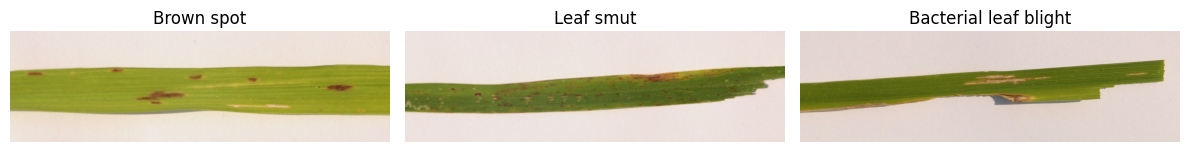

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

data_path = "/content/RiceLeaf/Data"

classes = {
    "Brown spot": "Brown spot-20200814T055208Z-001/Brown spot",
    "Leaf smut": "Leaf smut-20200814T055530Z-001/Leaf smut",
    "Bacterial leaf blight": "Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight"
}

plt.figure(figsize=(12, 4))

for i, (class_name, relative_path) in enumerate(classes.items()):
    folder_path = os.path.join(data_path, relative_path)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_path = os.path.join(folder_path, image_files[0])
    image = Image.open(image_path)

    plt.subplot(1, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import shutil

source_path = "/content/RiceLeaf/Data"
dataset_path = "/content/Rice_Dataset"

classes = {
    "Brown spot": "Brown spot-20200814T055208Z-001/Brown spot",
    "Leaf smut": "Leaf smut-20200814T055530Z-001/Leaf smut",
    "Bacterial leaf blight": "Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight"
}

os.makedirs(dataset_path, exist_ok=True)

for class_name, relative_path in classes.items():
    source_folder = os.path.join(source_path, relative_path)
    target_folder = os.path.join(dataset_path, class_name)

    os.makedirs(target_folder, exist_ok=True)

    for file in os.listdir(source_folder):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            shutil.copy(
                os.path.join(source_folder, file),
                os.path.join(target_folder, file)
            )

print("Dataset prepared successfully!")
print(os.listdir(dataset_path))

Dataset prepared successfully!
['Brown spot', 'Leaf smut', 'Bacterial leaf blight']


In [ ]:
import os

dataset_path = "/content/Rice_Dataset"

for class_name in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, class_name)

    count = len([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(f"{class_name} → {count} images")

Brown spot → 40 images
Leaf smut → 39 images
Bacterial leaf blight → 40 images


In [ ]:
import tensorflow as tf

IMG_SIZE = 128
BATCH_SIZE = 16

dataset = tf.keras.utils.image_dataset_from_directory(
    "/content/Rice_Dataset",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

print("Classes:", dataset.class_names)

Found 119 files belonging to 3 classes.
Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


In [ ]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    "/content/Rice_Dataset",
    image_size=(128, 128),
    batch_size=16,
    validation_split=0.2,
    subset="training",
    seed=42
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    "/content/Rice_Dataset",
    image_size=(128, 128),
    batch_size=16,
    validation_split=0.2,
    subset="validation",
    seed=42
)

print("Training images:", tf.data.experimental.cardinality(train_dataset).numpy() * 16)
print("Validation batches:", tf.data.experimental.cardinality(val_dataset).numpy())

Found 119 files belonging to 3 classes.
Using 96 files for training.
Found 119 files belonging to 3 classes.
Using 23 files for validation.
Training images: 96
Validation batches: 2


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15
)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 675ms/step - accuracy: 0.3542 - loss: 1.2463 - val_accuracy: 0.3478 - val_loss: 1.1203
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 801ms/step - accuracy: 0.4479 - loss: 1.0937 - val_accuracy: 0.3478 - val_loss: 1.1587
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 569ms/step - accuracy: 0.5208 - loss: 1.0225 - val_accuracy: 0.2609 - val_loss: 1.1358
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 569ms/step - accuracy: 0.5208 - loss: 0.9243 - val_accuracy: 0.3913 - val_loss: 1.0870
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 871ms/step - accuracy: 0.5417 - loss: 0.9247 - val_accuracy: 0.3478 - val_loss: 1.1928
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 644ms/step - accuracy: 0.5417 - loss: 0.9195 - val_accuracy: 0.5652 - val_loss: 0.8933
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 688ms/step - accuracy: 0.6146 - loss: 0.8085 - val_accuracy: 0.5652 - val_loss: 0.8885
Epoch 8/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 569ms/step - accuracy: 0.6771 - loss: 0.7367 - val_accuracy: 0.3478 - val_loss:

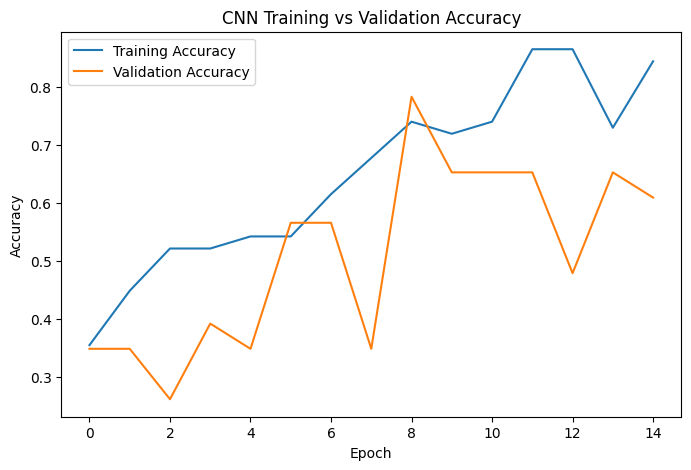

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
id="e5n731"
loss, accuracy = model.evaluate(val_dataset)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.6087 - loss: 0.8403
Validation Loss: 0.840305507183075
Validation Accuracy: 0.6086956262588501


In [ ]:
# Check available variables
print([x for x in globals() if 'val' in x.lower() or 'test' in x.lower() or 'dataset' in x.lower()])

[]


In [ ]:
import os

print(os.listdir())

['.config', 'sample_data']


In [ ]:
!pip install -U google-colab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 23.6 MB/s  0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving PRCP-1001-RiceLeaf.zip to PRCP-1001-RiceLeaf.zip


In [12]:
import os

print(os.listdir("/content"))

['.config', 'PRCP-1001-RiceLeaf.zip', 'sample_data']


In [13]:
import zipfile
import os

zip_path = "/content/PRCP-1001-RiceLeaf.zip"
extract_path = "/content/RiceLeaf"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted!")
print(os.listdir(extract_path))

Extracted!
['Data']


In [14]:
import zipfile
import os

data_path = "/content/RiceLeaf/Data"

for file in os.listdir(data_path):
    if file.endswith(".zip"):
        zip_path = os.path.join(data_path, file)
        extract_folder = os.path.join(data_path, file.replace(".zip", ""))

        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(extract_folder)

print("All disease files extracted!")

All disease files extracted!


In [15]:
import os
import shutil

source_path = "/content/RiceLeaf/Data"
dataset_path = "/content/Rice_Dataset"

classes = {
    "Brown spot": "Brown spot-20200814T055208Z-001/Brown spot",
    "Leaf smut": "Leaf smut-20200814T055530Z-001/Leaf smut",
    "Bacterial leaf blight": "Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight"
}

os.makedirs(dataset_path, exist_ok=True)

for class_name, relative_path in classes.items():
    source_folder = os.path.join(source_path, relative_path)
    target_folder = os.path.join(dataset_path, class_name)

    os.makedirs(target_folder, exist_ok=True)

    for file in os.listdir(source_folder):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            shutil.copy(
                os.path.join(source_folder, file),
                os.path.join(target_folder, file)
            )

print("Rice_Dataset created successfully!")
print(os.listdir(dataset_path))

Rice_Dataset created successfully!
['Brown spot', 'Leaf smut', 'Bacterial leaf blight']


In [16]:
import tensorflow as tf

train_dataset = tf.keras.utils.image_dataset_from_directory(
    "/content/Rice_Dataset",
    image_size=(128, 128),
    batch_size=16,
    validation_split=0.2,
    subset="training",
    seed=42
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    "/content/Rice_Dataset",
    image_size=(128, 128),
    batch_size=16,
    validation_split=0.2,
    subset="validation",
    seed=42
)

print("Train and validation datasets ready!")
print("Classes:", train_dataset.class_names)

Found 119 files belonging to 3 classes.
Using 96 files for training.
Found 119 files belonging to 3 classes.
Using 23 files for validation.
Train and validation datasets ready!
Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


In [17]:
print("Model exists:", "model" in globals())

Model exists: False


In [18]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model created successfully!")

CNN model created successfully!


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [19]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15
)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 870ms/step - accuracy: 0.4375 - loss: 1.1465 - val_accuracy: 0.3478 - val_loss: 1.1536
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 590ms/step - accuracy: 0.4792 - loss: 1.0037 - val_accuracy: 0.3478 - val_loss: 1.0186
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 579ms/step - accuracy: 0.6146 - loss: 0.8707 - val_accuracy: 0.3478 - val_loss: 1.4773
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 739ms/step - accuracy: 0.5938 - loss: 0.8926 - val_accuracy: 0.5217 - val_loss: 0.8998
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 518ms/step - accuracy: 0.6875 - loss: 0.7434 - val_accuracy: 0.3478 - val_loss: 1.2188
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 520ms/step - accuracy: 0.6250 - loss: 0.8148 - val_accuracy: 0.8696 - val_loss: 0.8020
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 721ms/step - accuracy: 0.7917 - loss: 0.5943 - val_accuracy: 0.6522 - val_loss: 0.7968
Epoch 8/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 517ms/step - accuracy: 0.8542 - loss: 0.4208 - val_accuracy: 0.5217 - val_loss:

In [20]:
loss, accuracy = model.evaluate(val_dataset)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.8261 - loss: 0.8626
Validation Loss: 0.8625577688217163
Validation Accuracy: 0.8260869383811951


Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      1.00      1.00         7
           Brown spot       0.60      0.60      0.60         5
            Leaf smut       0.82      0.82      0.82        11

             accuracy                           0.83        23
            macro avg       0.81      0.81      0.81        23
         weighted avg       0.83      0.83      0.83        23



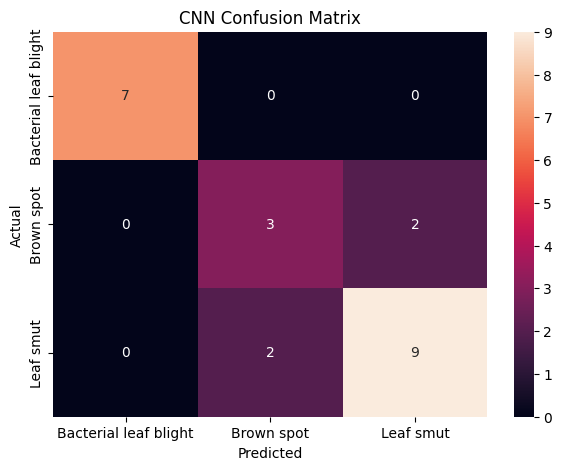

In [21]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

y_true = []
y_pred = []

for images, labels in val_dataset:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

class_names = val_dataset.class_names

print("Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.show()

In [22]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15)
])

print("Data augmentation created successfully!")

Data augmentation created successfully!


In [23]:
from tensorflow.keras import layers, models

aug_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax")
])

aug_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN model created successfully!")

Augmented CNN model created successfully!


In [24]:
aug_history = aug_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15
)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 681ms/step - accuracy: 0.3854 - loss: 1.3148 - val_accuracy: 0.2174 - val_loss: 1.1379
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 831ms/step - accuracy: 0.3854 - loss: 1.0797 - val_accuracy: 0.2174 - val_loss: 1.1803
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 590ms/step - accuracy: 0.3542 - loss: 1.0914 - val_accuracy: 0.2609 - val_loss: 1.1482
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 645ms/step - accuracy: 0.3958 - loss: 1.0218 - val_accuracy: 0.3478 - val_loss: 1.1557
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 645ms/step - accuracy: 0.4583 - loss: 1.0165 - val_accuracy: 0.6522 - val_loss: 1.0130
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 646ms/step - accuracy: 0.4479 - loss: 1.0736 - val_accuracy: 0.3478 - val_loss: 1.0595
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 756ms/step - accuracy: 0.5625 - loss: 0.9155 - val_accuracy: 0.3478 - val_loss: 1.2135
Epoch 8/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 593ms/step - accuracy: 0.5208 - loss: 0.9176 - val_accuracy: 0.5652 - val_loss:

In [25]:
print("Original CNN Best Validation Accuracy:",
      max(history.history["val_accuracy"]))

print("Augmented CNN Best Validation Accuracy:",
      max(aug_history.history["val_accuracy"]))

Original CNN Best Validation Accuracy: 0.8695651888847351
Augmented CNN Best Validation Accuracy: 0.739130437374115


In [26]:
final_loss, final_accuracy = model.evaluate(val_dataset)

print("FINAL MODEL: Original CNN")
print("Final Validation Loss:", final_loss)
print("Final Validation Accuracy:", final_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.8261 - loss: 0.8626
FINAL MODEL: Original CNN
Final Validation Loss: 0.8625577688217163
Final Validation Accuracy: 0.8260869383811951


In [27]:
model.save("/content/Final_Rice_Leaf_Disease_CNN.keras")

print("Final CNN model saved successfully!")

Final CNN model saved successfully!


In [28]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Original CNN",
        "CNN with Data Augmentation"
    ],
    "Best Validation Accuracy": [
        max(history.history["val_accuracy"]) * 100,
        max(aug_history.history["val_accuracy"]) * 100
    ],
    "Final Validation Accuracy": [
        final_accuracy * 100,
        aug_model.evaluate(val_dataset, verbose=0)[1] * 100
    ]
})

comparison

,Model,Best Validation Accuracy,Final Validation Accuracy
0,Original CNN,86.956519,82.608694
1,CNN with Data Augmentation,73.913044,73.913044


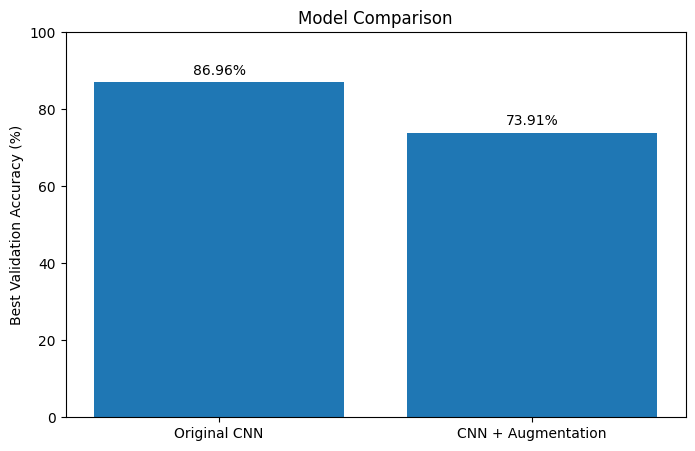

In [29]:
plt.figure(figsize=(8, 5))

models = ["Original CNN", "CNN + Augmentation"]
accuracies = [
    max(history.history["val_accuracy"]) * 100,
    max(aug_history.history["val_accuracy"]) * 100
]

plt.bar(models, accuracies)

plt.ylabel("Best Validation Accuracy (%)")
plt.title("Model Comparison")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.show()

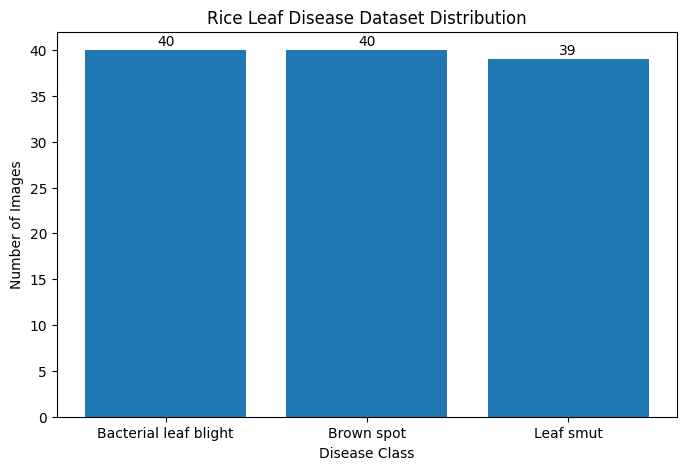

In [30]:
import matplotlib.pyplot as plt

class_names = [
    "Bacterial leaf blight",
    "Brown spot",
    "Leaf smut"
]

image_counts = [40, 40, 39]

plt.figure(figsize=(8, 5))
bars = plt.bar(class_names, image_counts)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title("Rice Leaf Disease Dataset Distribution")

for bar, count in zip(bars, image_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + 0.5,
        str(count),
        ha="center"
    )

plt.show()

In [31]:
from PIL import Image
import os
import pandas as pd

data_path = "/content/Rice_Dataset"

image_info = []

for class_name in os.listdir(data_path):
    class_path = os.path.join(data_path, class_name)

    for file in os.listdir(class_path):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(class_path, file)

            with Image.open(image_path) as img:
                width, height = img.size

            image_info.append({
                "Class": class_name,
                "Width": width,
                "Height": height
            })

image_df = pd.DataFrame(image_info)

print("Total images:", len(image_df))
print("\nUnique image sizes:")
print(image_df[["Width", "Height"]].drop_duplicates().to_string(index=False))

Total images: 119

Unique image sizes:
 Width  Height
  3081     897
   456     124
   316     127
  1200     900
   766     250
   359     168
   296      88
  1504     323
   699     197
   765     224
   467     104
   768     514
  1480     279
   763     268
   311     170
   617     244
   340      94
   427     193
   286      92
  1530     371
   741     291
   250     200
   948     233
   565     233
   510     383
   503     174
   946     255
   948     211
   537     216
   614     409
   562     217
   376      80
   367      73
   301      71


In [32]:
from PIL import Image
import os
from collections import Counter

data_path = "/content/Rice_Dataset"

image_modes = []

for class_name in os.listdir(data_path):
    class_path = os.path.join(data_path, class_name)

    for file in os.listdir(class_path):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(class_path, file)

            with Image.open(image_path) as img:
                image_modes.append(img.mode)

print("Image color modes:")
print(Counter(image_modes))

Image color modes:
Counter({'RGB': 119})


In [33]:
print("===== DATASET SUMMARY =====")
print("Total Images:", len(image_df))
print("Number of Classes:", image_df["Class"].nunique())

print("\nImages per Class:")
print(image_df["Class"].value_counts())

print("\nImage Width:")
print("Minimum:", image_df["Width"].min())
print("Maximum:", image_df["Width"].max())

print("\nImage Height:")
print("Minimum:", image_df["Height"].min())
print("Maximum:", image_df["Height"].max())

print("\nColor Mode: RGB for all 119 images")

===== DATASET SUMMARY =====
Total Images: 119
Number of Classes: 3

Images per Class:
Class
Brown spot               40
Bacterial leaf blight    40
Leaf smut                39
Name: count, dtype: int64

Image Width:
Minimum: 250
Maximum: 3081

Image Height:
Minimum: 71
Maximum: 900

Color Mode: RGB for all 119 images


In [34]:
challenges = {
    "Challenge": [
        "Small dataset",
        "Different image dimensions",
        "Class imbalance",
        "Limited validation samples",
        "Data augmentation did not improve performance"
    ],
    "Technique / Solution": [
        "Used CNN for image classification",
        "Resized all images to 128 × 128",
        "Used the available dataset and monitored class distribution",
        "Used an 80:20 training-validation split",
        "Compared augmented CNN with original CNN and selected the better model"
    ]
}

challenges_df = pd.DataFrame(challenges)

challenges_df

,Challenge,Technique / Solution
0,Small dataset,Used CNN for image classification
1,Different image dimensions,Resized all images to 128 × 128
2,Class imbalance,Used the available dataset and monitored class...
3,Limited validation samples,Used an 80:20 training-validation split
4,Data augmentation did not improve performance,Compared augmented CNN with original CNN and s...


In [35]:
print("""
===== PROJECT CONCLUSION =====

The Rice Leaf Disease Detection project classifies rice leaf images
into three disease classes: Bacterial leaf blight, Brown spot, and Leaf smut.

A CNN model was developed and trained using 119 available images.
All images were resized to 128 x 128 pixels and normalized before training.

Two approaches were compared:
1. Original CNN
2. CNN with Data Augmentation

The Original CNN performed better in our experiment, achieving a best
validation accuracy of 86.96% and a final validation accuracy of 82.61%.

The augmented CNN achieved a best validation accuracy of 73.91%.
Therefore, the Original CNN was selected as the final production model.

The final model was saved as:
Final_Rice_Leaf_Disease_CNN.keras
""")


===== PROJECT CONCLUSION =====

The Rice Leaf Disease Detection project classifies rice leaf images
into three disease classes: Bacterial leaf blight, Brown spot, and Leaf smut.

A CNN model was developed and trained using 119 available images.
All images were resized to 128 x 128 pixels and normalized before training.

Two approaches were compared:
1. Original CNN
2. CNN with Data Augmentation

The Original CNN performed better in our experiment, achieving a best
validation accuracy of 86.96% and a final validation accuracy of 82.61%.

The augmented CNN achieved a best validation accuracy of 73.91%.
Therefore, the Original CNN was selected as the final production model.

The final model was saved as:
Final_Rice_Leaf_Disease_CNN.keras

